# Ejercicio 2 · Tipologías de municipios con PCA y K-Means

El IPM resume la pobreza en un solo número, pero dos municipios con el mismo IPM pueden ser pobres por razones muy distintas: uno por falta de acueducto y pisos de tierra, otro por informalidad laboral y bajo logro educativo. Para diseñar política pública conviene agruparlos según **la estructura** de sus privaciones y no solo según su nivel.

Usamos las 15 privaciones del IPM municipal del Censo 2018 para 1.122 municipios. Primero reducimos la dimensión con Análisis de Componentes Principales (PCA) para entender qué ejes organizan la pobreza en Colombia; luego agrupamos con K-Means sobre esos componentes y describimos cada grupo.

**Datos:** DANE, IPM municipal por privación, CNPV 2018 (porcentaje de personas en hogares con cada privación). Base tomada del repositorio público *SAE Pobreza 2026* (PUJ Cali) y cruzada con la división política del Marco Geoestadístico Nacional 2018.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import warnings; warnings.filterwarnings('ignore')

DATOS = Path('datos')   # en Colab, sube la carpeta datos/ al entorno
SEMILLA = 42

def encuadre(ax):
    """Encuadra el mapa en Colombia continental (San Andrés queda fuera del recuadro)."""
    ax.set_xlim(-79.3, -66.7); ax.set_ylim(-4.4, 12.6); ax.set_axis_off()

In [2]:
# Estilo gráfico común (paleta validada para daltonismo)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, ROJO = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
GRIS, TINTA, TINTA2 = '#898781', '#0b0b0b', '#52514e'
SEQ = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#1c5cab', '#86b6ef', '#f0efec', '#ee9a99', '#b02e2e'])

mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})

# Los grupos quedarán ordenados por nivel de privación, así que usamos una escala ordinal de un solo tono
TONOS_GRUPO = ['#b7d3f6', '#5598e7', '#1c5cab', '#0d366b']

## 1. Datos y exploración

In [3]:
df = pd.read_csv(DATOS / 'ej2_privaciones_ipm_2018.csv')
privaciones = df.columns[5:20].tolist()
print(df.shape); print(privaciones)
df[privaciones + ['ipm']].describe().T.round(1)

(1122, 21)
['analfabetismo', 'bajo_logro_educativo', 'barreras_primera_infancia', 'barreras_acceso_salud', 'tasa_dependencia', 'hacinamiento_critico', 'inadecuada_elim_excretas', 'inasistencia_escolar', 'paredes_inadecuadas', 'pisos_inadecuados', 'rezago_escolar', 'sin_agua_mejorada', 'sin_aseguramiento_salud', 'trabajo_infantil', 'trabajo_informal']


,count,mean,std,min,25%,50%,75%,max
analfabetismo,1122.0,17.4,8.0,2.0,11.9,16.2,21.4,52.5
bajo_logro_educativo,1122.0,67.0,12.7,18.3,61.0,69.9,76.0,96.2
barreras_primera_infancia,1122.0,2.6,3.3,0.4,1.3,1.8,2.6,34.6
barreras_acceso_salud,1122.0,5.1,4.1,0.0,2.3,4.2,6.6,40.2
tasa_dependencia,1122.0,41.1,12.9,14.7,32.1,39.3,48.2,97.7
hacinamiento_critico,1122.0,11.2,7.5,1.4,5.6,8.7,15.4,58.1
inadecuada_elim_excretas,1122.0,24.3,22.1,0.2,7.7,17.0,34.7,98.7
inasistencia_escolar,1122.0,5.1,3.6,0.9,3.0,4.3,6.1,42.8
paredes_inadecuadas,1122.0,5.2,8.2,0.0,0.6,2.1,6.2,72.7
pisos_inadecuados,1122.0,15.7,16.8,0.0,3.0,9.6,22.7,86.7


Las escalas son muy distintas: el trabajo informal está por encima del 80 % en casi todos los municipios, mientras que el trabajo infantil rara vez pasa del 5 %. Si no estandarizamos, las variables con mayor varianza dominarían tanto el PCA como las distancias de K-Means.

Antes de reducir dimensiones vale la pena ver cuánto se correlacionan las privaciones entre sí; el PCA solo es útil si hay redundancia.

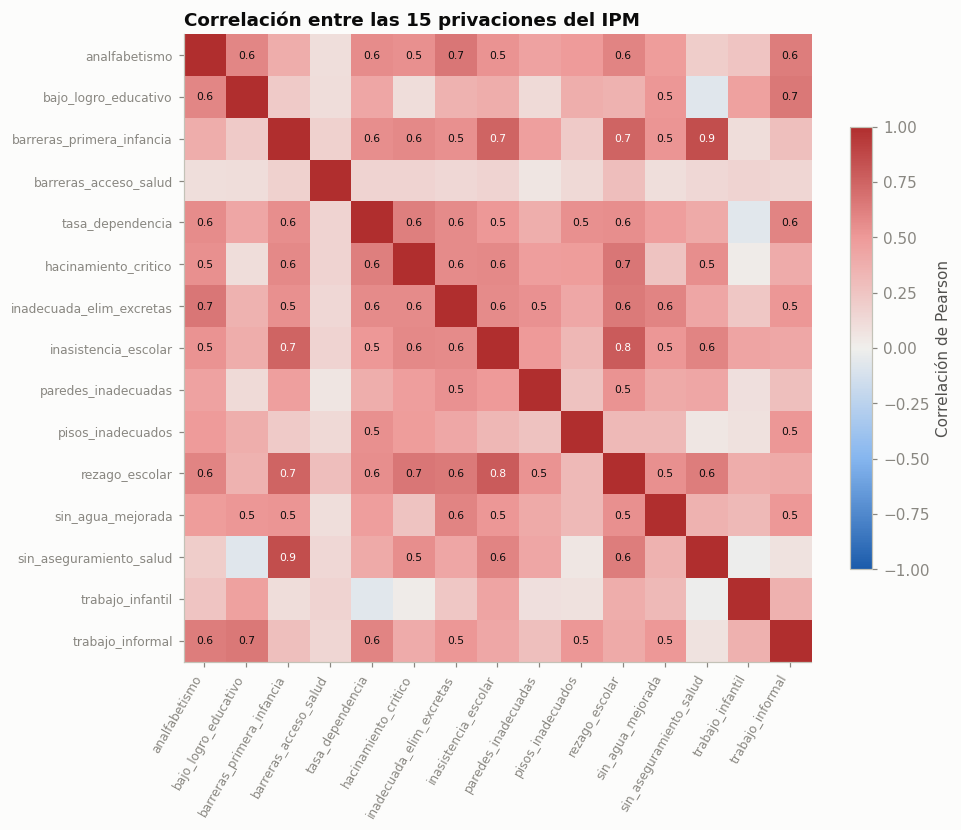

In [4]:
corr = df[privaciones].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(privaciones)), privaciones, rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(len(privaciones)), privaciones, fontsize=8)
ax.grid(False)
for i in range(len(privaciones)):
    for j in range(len(privaciones)):
        if i != j and abs(corr.iloc[i, j]) >= 0.5:
            ax.text(j, i, f'{corr.iloc[i, j]:.1f}', ha='center', va='center', fontsize=7,
                    color='white' if abs(corr.iloc[i, j]) > 0.7 else TINTA)
fig.colorbar(im, ax=ax, shrink=0.7, label='Correlación de Pearson')
ax.set_title('Correlación entre las 15 privaciones del IPM')
plt.tight_layout(); plt.show()

Casi todas las correlaciones son positivas: donde falta acueducto también suele haber problemas de excretas, rezago escolar y analfabetismo. Esa redundancia es justo lo que el PCA aprovecha.

## 2. Estandarización y PCA

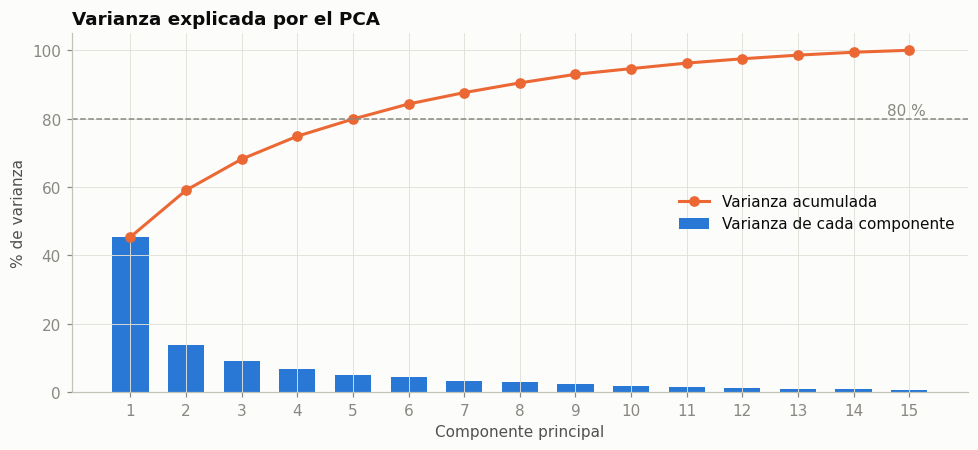

PC1 explica 45.4%; con 6 componentes se retiene 84.3% de la varianza


In [5]:
Z = StandardScaler().fit_transform(df[privaciones])
pca_completo = PCA().fit(Z)
var = pca_completo.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(1, len(var) + 1)
ax.bar(x, var * 100, color=AZUL, width=0.65, label='Varianza de cada componente')
ax.plot(x, var.cumsum() * 100, color=NARANJA, marker='o', ms=6, label='Varianza acumulada')
ax.axhline(80, color=GRIS, ls='--', lw=1); ax.text(15.3, 81, '80 %', color=GRIS, ha='right')
ax.set(xticks=x, xlabel='Componente principal', ylabel='% de varianza', title='Varianza explicada por el PCA', ylim=(0, 105))
ax.legend(loc='center right'); plt.tight_layout(); plt.show()

n_comp = int(np.argmax(var.cumsum() >= 0.80) + 1)
print(f'PC1 explica {var[0]:.1%}; con {n_comp} componentes se retiene {var[:n_comp].sum():.1%} de la varianza')

El primer componente solo ya recoge cerca de la mitad de la información de las 15 privaciones. Para agrupar retenemos los componentes necesarios para llegar al 80 % de la varianza; el resto se trata como ruido.

¿Qué significa cada componente? Lo leemos en las cargas (el peso de cada privación en el componente).

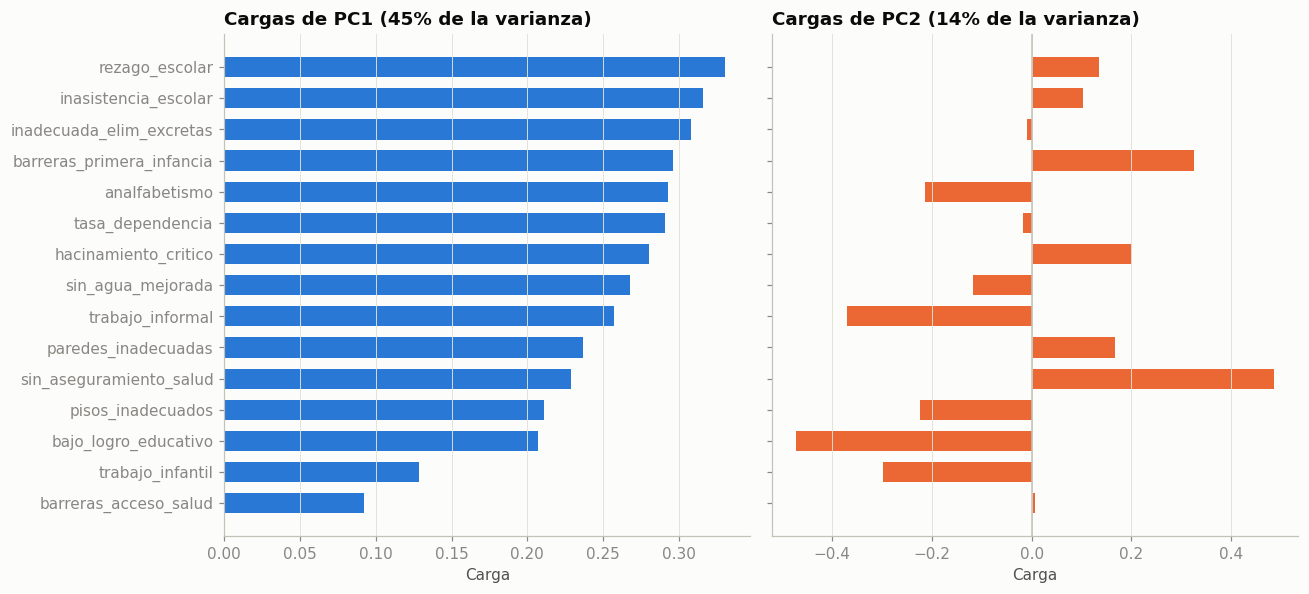

,PC1,PC2,PC3
rezago_escolar,0.33,0.14,0.20
inasistencia_escolar,0.32,0.10,0.25
inadecuada_elim_excretas,0.31,-0.01,-0.06
barreras_primera_infancia,0.30,0.33,0.13
analfabetismo,0.29,-0.21,-0.14
tasa_dependencia,0.29,-0.02,-0.36
hacinamiento_critico,0.28,0.20,-0.28
sin_agua_mejorada,0.27,-0.12,0.16
trabajo_informal,0.26,-0.37,-0.11
paredes_inadecuadas,0.24,0.17,-0.06


In [6]:
cargas = pd.DataFrame(pca_completo.components_[:3].T, index=privaciones, columns=['PC1', 'PC2', 'PC3'])
# Orientamos PC1 para que valores altos signifiquen más privación
if cargas.PC1.sum() < 0:
    cargas.PC1 *= -1
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
for a, pc, color in zip(ax, ['PC1', 'PC2'], [AZUL, NARANJA]):
    s = cargas[pc].sort_values()
    a.barh(s.index, s.values, color=color, height=0.65)
    a.axvline(0, color='#c3c2b7', lw=1); a.grid(axis='y', visible=False)
    a.set(title=f'Cargas de {pc} ({var[int(pc[-1]) - 1]:.0%} de la varianza)', xlabel='Carga')
plt.tight_layout(); plt.show()
cargas.round(2).sort_values('PC1', ascending=False)

**PC1 es un eje general de privación**: todas las cargas son positivas y de tamaño similar. Un municipio con PC1 alto tiene más de todo: más analfabetismo, peor agua, más hacinamiento, más rezago escolar.

**PC2 separa dos tipos de pobreza.** De un lado quedan las privaciones de acceso a servicios del Estado (sin aseguramiento en salud, barreras para la primera infancia, hacinamiento); del otro, las privaciones ligadas a la economía rural tradicional (bajo logro educativo, trabajo informal, trabajo infantil, pisos de tierra). Es un eje de "tipo" de pobreza más que de nivel.

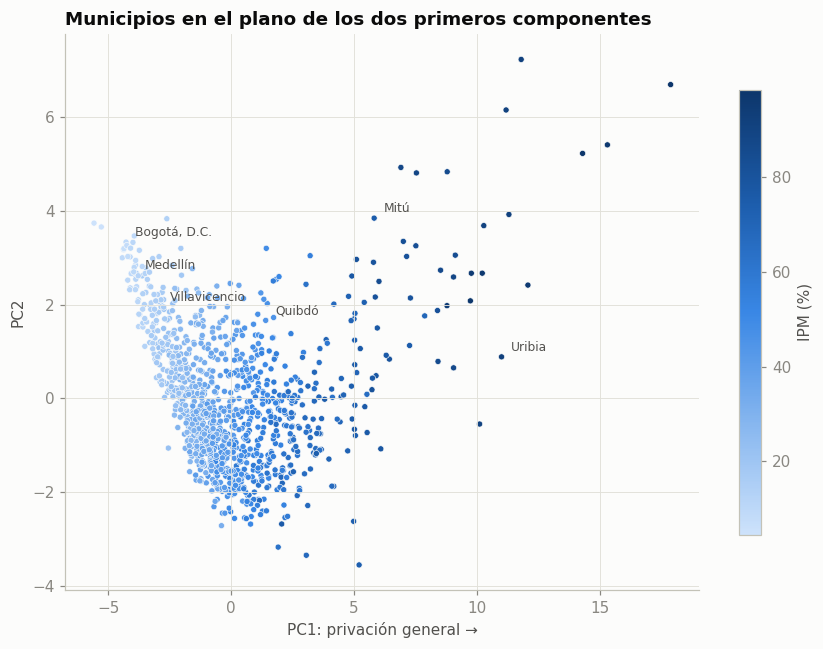

In [7]:
P = PCA(n_components=n_comp).fit_transform(Z)
if np.corrcoef(P[:, 0], df.ipm)[0, 1] < 0:
    P[:, 0] *= -1

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(P[:, 0], P[:, 1], c=df.ipm, cmap=SEQ, s=16, edgecolor='#fcfcfb', linewidth=0.4)
fig.colorbar(sc, ax=ax, label='IPM (%)', shrink=0.8)
for nombre in ['Bogotá, D.C.', 'Medellín', 'Villavicencio', 'Quibdó', 'Uribia', 'Mitú']:
    i = df.index[df.municipio.str.lower() == nombre.lower()]
    if len(i):
        ax.annotate(nombre, (P[i[0], 0], P[i[0], 1]), xytext=(6, 4), textcoords='offset points', fontsize=8, color=TINTA2)
ax.set(xlabel='PC1: privación general →', ylabel='PC2', title='Municipios en el plano de los dos primeros componentes')
plt.tight_layout(); plt.show()

El IPM crece casi en línea recta con PC1, como era de esperar. Lo interesante está en la dispersión vertical: a igual nivel de pobreza, los municipios se reparten a lo largo de PC2 según el tipo de privación que predomina.

## 3. ¿Cuántos grupos?

Aplicamos K-Means sobre los componentes retenidos con distintos valores de *k* y revisamos dos criterios: la inercia (suma de distancias al centroide, el "codo") y el coeficiente de silueta (qué tan bien separado está cada municipio de los grupos vecinos).

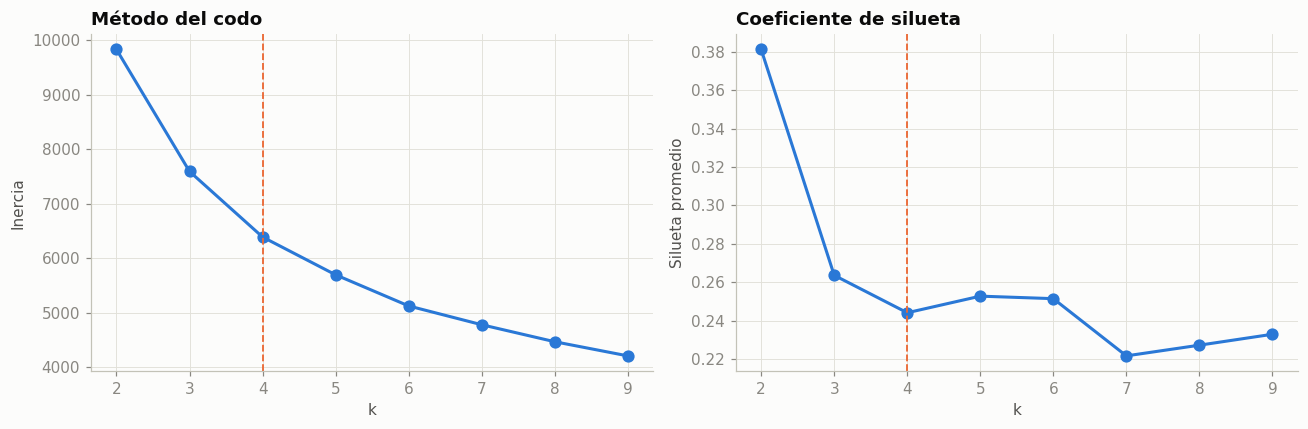

,k,inercia,silueta
0,2,9834.281,0.381
1,3,7593.595,0.264
2,4,6389.182,0.244
3,5,5694.792,0.253
4,6,5122.950,0.251
5,7,4777.605,0.222
6,8,4465.225,0.227
7,9,4205.348,0.233


In [8]:
ks = range(2, 10)
res = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=SEMILLA).fit(P)
    res.append({'k': k, 'inercia': km.inertia_, 'silueta': silhouette_score(P, km.labels_)})
res = pd.DataFrame(res)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(res.k, res.inercia, color=AZUL, marker='o', ms=7)
ax[0].set(title='Método del codo', xlabel='k', ylabel='Inercia')
ax[1].plot(res.k, res.silueta, color=AZUL, marker='o', ms=7)
ax[1].set(title='Coeficiente de silueta', xlabel='k', ylabel='Silueta promedio')
for a in ax: a.axvline(4, color=NARANJA, ls='--', lw=1.2)
plt.tight_layout(); plt.show()
res.round(3)

La silueta más alta aparece con *k* = 2, pero esa partición es casi trivial: separa municipios pobres de no pobres, algo que ya sabíamos con el IPM. El codo se suaviza entre 3 y 5 grupos y la silueta se mantiene estable en ese rango. Elegimos **k = 4** porque produce grupos interpretables que difieren en el *tipo* de privación y no solo en el nivel. Es una decisión analítica, no automática, y hay que justificarla así.

## 4. K-Means con k = 4 y perfil de los grupos

In [9]:
K = 4
km = KMeans(n_clusters=K, n_init=100, random_state=SEMILLA).fit(P)
df['grupo_km'] = km.labels_

# Renumeramos los grupos de menor a mayor IPM promedio para que la lectura sea ordenada
orden = df.groupby('grupo_km').ipm.mean().sort_values().index
df['grupo'] = df.grupo_km.map({g: i + 1 for i, g in enumerate(orden)})

perfil = df.groupby('grupo')[privaciones + ['ipm']].mean()
perfil['municipios'] = df.grupo.value_counts().sort_index()
perfil.T.round(1)

grupo,1,2,3,4
analfabetismo,10.0,16.7,24.4,30.2
bajo_logro_educativo,52.7,73.7,68.7,79.3
barreras_primera_infancia,1.8,1.6,3.2,14.5
barreras_acceso_salud,4.2,4.9,6.0,7.0
tasa_dependencia,30.9,39.9,48.9,70.8
hacinamiento_critico,7.8,7.8,17.8,25.9
inadecuada_elim_excretas,7.5,19.0,43.0,72.2
inasistencia_escolar,3.2,4.3,6.8,14.9
paredes_inadecuadas,2.4,2.4,9.7,22.4
pisos_inadecuados,3.7,14.9,28.9,23.9


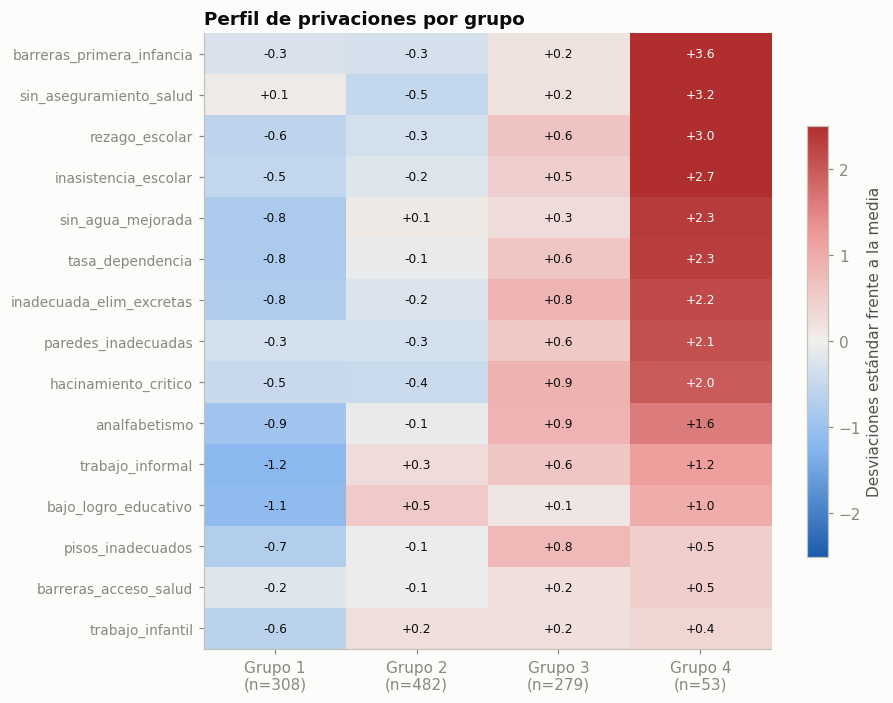

In [10]:
# Mapa de calor de perfiles: diferencia de cada grupo frente a la media nacional, en desviaciones estándar
zperfil = pd.DataFrame(Z, columns=privaciones).groupby(df.grupo).mean()
orden_var = zperfil.loc[K].sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = ax.imshow(zperfil[orden_var].T, cmap=DIV, vmin=-2.5, vmax=2.5, aspect='auto')
ax.set_xticks(range(K), [f'Grupo {g}\n(n={n})' for g, n in perfil.municipios.items()])
ax.set_yticks(range(len(orden_var)), orden_var, fontsize=9); ax.grid(False)
for i, v in enumerate(orden_var):
    for j, g in enumerate(zperfil.index):
        val = zperfil.loc[g, v]
        ax.text(j, i, f'{val:+.1f}', ha='center', va='center', fontsize=8, color='white' if abs(val) > 1.6 else TINTA)
fig.colorbar(im, ax=ax, shrink=0.7, label='Desviaciones estándar frente a la media')
ax.set_title('Perfil de privaciones por grupo')
plt.tight_layout(); plt.show()

Con base en los perfiles damos un nombre a cada grupo:

- **Grupo 1 · Baja privación** (308 municipios, IPM medio 23 %). Todas las privaciones por debajo de la media, con la menor informalidad laboral. Incluye las capitales y muchos municipios intermedios bien conectados.
- **Grupo 2 · Privación media con bajo logro educativo** (482 municipios, IPM 41 %). Cerca de la media en casi todo; su rasgo distintivo es el bajo logro educativo de los adultos con buena cobertura de aseguramiento en salud. Es el grupo más numeroso y predomina en la zona andina.
- **Grupo 3 · Déficit de vivienda y saneamiento** (279 municipios, IPM 57 %). Hacinamiento, analfabetismo, pisos de tierra y eliminación inadecuada de excretas claramente por encima de la media.
- **Grupo 4 · Privación extrema y dispersa** (53 municipios, IPM 83 %). Entre 2 y 3,6 desviaciones estándar por encima de la media en casi todo, sobre todo en barreras para la primera infancia, falta de aseguramiento en salud, rezago e inasistencia escolar y agua no mejorada.

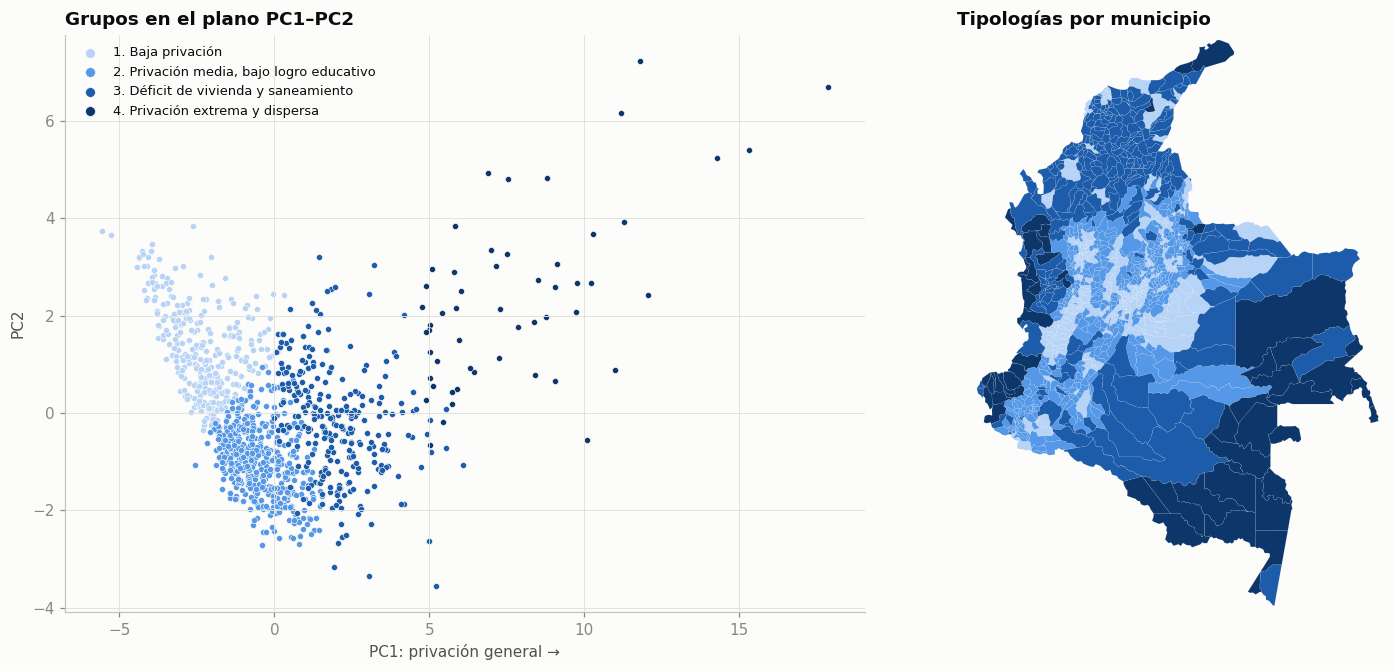

In [11]:
nombres = {1: 'Baja privación', 2: 'Privación media, bajo logro educativo',
           3: 'Déficit de vivienda y saneamiento', 4: 'Privación extrema y dispersa'}
df['tipologia'] = df.grupo.map(nombres)

fig, ax = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={'width_ratios': [1.15, 1]})
for g in range(1, K + 1):
    m = df.grupo == g
    ax[0].scatter(P[m, 0], P[m, 1], s=16, color=TONOS_GRUPO[g - 1], edgecolor='#fcfcfb', linewidth=0.4,
                  label=f'{g}. {nombres[g]}')
ax[0].set(xlabel='PC1: privación general →', ylabel='PC2', title='Grupos en el plano PC1–PC2')
ax[0].legend(loc='upper left', fontsize=8.5, markerscale=1.6)

mapa = gpd.read_file(DATOS / 'municipios_colombia.geojson').merge(df[['cod_mpio', 'grupo']], on='cod_mpio', how='left')
for g in range(1, K + 1):
    mapa[mapa.grupo == g].plot(ax=ax[1], color=TONOS_GRUPO[g - 1], linewidth=0.05, edgecolor='white')
mapa[mapa.grupo.isna()].plot(ax=ax[1], color='#e1e0d9')
ax[1].set_title('Tipologías por municipio'); encuadre(ax[1])
plt.tight_layout(); plt.show()

In [12]:
tabla = pd.crosstab(df.region, df.tipologia, normalize='index').mul(100).round(1)[list(nombres.values())]
tabla['municipios'] = df.region.value_counts()
tabla

tipologia,Baja privación,"Privación media, bajo logro educativo",Déficit de vivienda y saneamiento,Privación extrema y dispersa,municipios
region,,,,,
Amazonía,10.2,25.4,23.7,40.7,59
Andina,33.2,58.2,7.9,0.6,629
Caribe,14.7,2.0,81.7,1.5,197
Orinoquía,40.7,27.1,30.5,1.7,59
Pacífica,22.5,45.5,20.2,11.8,178


La geografía aparece sin que el algoritmo la conociera: K-Means nunca recibió la región ni las coordenadas, y aun así el 82 % de los municipios del Caribe cae en el grupo 3 de déficit de vivienda y saneamiento, y el grupo 4 se concentra en la Amazonía y el Pacífico (41 % de los municipios amazónicos están en él). Esto sugiere que las privaciones tienen raíces territoriales (tipo de poblamiento, clima, dispersión rural) que una política nacional uniforme no alcanza a cubrir.

## 5. ¿Son estables los grupos?

K-Means depende de los centroides iniciales y de la muestra. Dos pruebas rápidas: repetir el algoritmo con otras semillas y reagruparlo con submuestras del 80 % de los municipios. Comparamos con el índice de Rand ajustado (ARI), que vale 1 cuando dos particiones coinciden por completo.

In [13]:
rng = np.random.default_rng(SEMILLA)
ari_semillas = [adjusted_rand_score(df.grupo_km, KMeans(K, n_init=10, random_state=s).fit_predict(P)) for s in range(20)]

ari_boot = []
for b in range(30):
    idx = rng.choice(len(P), size=int(0.8 * len(P)), replace=False)
    km_b = KMeans(K, n_init=20, random_state=b).fit(P[idx])
    ari_boot.append(adjusted_rand_score(df.grupo_km.values[idx], km_b.labels_))

print(f'ARI entre semillas:        media {np.mean(ari_semillas):.3f} · mínimo {np.min(ari_semillas):.3f}')
print(f'ARI con submuestras 80 %:  media {np.mean(ari_boot):.3f} · mínimo {np.min(ari_boot):.3f}')

# ¿Cambia algo si agrupamos con las 15 variables estandarizadas en vez de los componentes?
km_z = KMeans(K, n_init=50, random_state=SEMILLA).fit(Z)
print(f'ARI frente a K-Means sobre las 15 variables sin PCA: {adjusted_rand_score(df.grupo_km, km_z.labels_):.3f}')

ARI entre semillas:        media 0.999 · mínimo 0.994
ARI con submuestras 80 %:  media 0.913 · mínimo 0.794
ARI frente a K-Means sobre las 15 variables sin PCA: 0.836


La partición es prácticamente idéntica con cualquier semilla (ARI ≈ 1) y se mantiene alta con submuestras (ARI medio ≈ 0,9). También coincide en buena medida con la que se obtiene sin PCA (ARI ≈ 0,84): reducir a seis componentes no cambia la historia, pero la hace más fácil de visualizar y quita ruido. Como regla práctica, un ARI por encima de 0,8 indica una tipología robusta; valores bajos serían señal de que el número de grupos no está bien sustentado.

## 6. Zoom a un departamento

La tipología nacional sirve de marco para leer un territorio concreto. Cambie el departamento en la primera línea.

In [14]:
DEPTO = 'Meta'
sub = df[df.departamento.str.lower() == DEPTO.lower()]
print(sub.tipologia.value_counts().to_string(), '\n')
sub[['municipio', 'ipm', 'tipologia', 'sin_agua_mejorada', 'inadecuada_elim_excretas', 'bajo_logro_educativo', 'trabajo_informal']] \
    .sort_values('ipm').round(1).reset_index(drop=True)

tipologia
Baja privación                           14
Privación media, bajo logro educativo    10
Déficit de vivienda y saneamiento         5 



,municipio,ipm,tipologia,sin_agua_mejorada,inadecuada_elim_excretas,bajo_logro_educativo,trabajo_informal
0,Restrepo,15.3,Baja privación,6.3,2.7,41.7,78.8
1,Villavicencio,15.9,Baja privación,6.7,5.2,38.8,82.3
2,Acacías,19.2,Baja privación,4.4,1.5,45.4,78.8
3,Cubarral,21.8,Baja privación,13.8,6.8,55.8,85.3
4,Guamal,22.6,Baja privación,3.4,4.8,50.4,81.0
5,Cumaral,22.7,Baja privación,17.6,3.0,52.7,78.0
6,Castilla La Nueva,23.1,Baja privación,6.9,4.5,49.6,71.3
7,San Martín,25.5,Baja privación,6.2,2.7,59.2,79.3
8,El Dorado,28.9,"Privación media, bajo logro educativo",9.8,4.7,65.6,89.0
9,Granada,29.6,Baja privación,37.5,8.4,57.3,88.1


## 7. Conclusiones

Las 15 privaciones del IPM se resumen bien en pocos componentes: el primero es un eje general de pobreza y el segundo distingue la pobreza por falta de acceso a servicios del Estado de la pobreza ligada a la economía rural tradicional. Sobre ese espacio, K-Means con cuatro grupos produce una tipología estable y con sentido territorial, útil para focalizar: no es lo mismo intervenir un municipio del grupo 3, donde la prioridad es vivienda y saneamiento, que uno del grupo 4, donde faltan casi todos los servicios básicos a la vez.

## Retos para los estudiantes

1. Repita el ejercicio con *k* = 3 y *k* = 5. ¿Qué grupo se divide o se fusiona? ¿Cuál tipología comunicaría mejor a un tomador de decisiones?
2. Reemplace K-Means por un agrupamiento jerárquico (`AgglomerativeClustering` con enlace de Ward) y compare con el ARI.
3. Quite el trabajo informal (casi constante entre municipios) y vuelva a correr el PCA. ¿Cambian las cargas de PC2?
4. Cruce la tipología con la base del Ejercicio 1: ¿en qué grupos se equivoca más el Random Forest?